In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [8]:
df = pd.read_csv("ChargingRecords.csv")

In [9]:
df.shape

(72856, 13)

In [10]:
df.columns

Index(['UserID', 'ChargerID', 'ChargerCompany', 'Location', 'ChargerType',
       'StartDay', 'StartTime', 'EndDay', 'EndTime', 'StartDatetime',
       'EndDatetime', 'Duration', 'Demand'],
      dtype='object')

In [11]:
df.head()

,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,EndDatetime,Duration,Demand
0,0,1,1,hotel,0,2022-09-15,20:54:02,2022-09-15,23:59:13,2022-09-15 20:54,2022-09-15 23:59,185,20.36
1,0,1,1,hotel,0,2022-09-14,20:01:05,2022-09-14,21:31:04,2022-09-14 20:01,2022-09-14 21:31,90,10.19
2,0,1,1,hotel,0,2022-09-14,18:54:30,2022-09-14,19:54:29,2022-09-14 18:54,2022-09-14 19:54,60,6.78
3,0,1,1,hotel,0,2022-09-29,18:32:51,2022-09-30,0:16:42,2022-09-29 18:32,2022-09-30 0:16,344,37.65
4,0,1,1,hotel,0,2022-09-25,19:30:15,2022-09-26,0:30:14,2022-09-25 19:30,2022-09-26 0:30,300,33.81


In [12]:
df.dtypes

UserID              int64
ChargerID           int64
ChargerCompany      int64
Location           object
ChargerType         int64
StartDay           object
StartTime          object
EndDay             object
EndTime            object
StartDatetime      object
EndDatetime        object
Duration            int64
Demand            float64
dtype: object

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72856 entries, 0 to 72855
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   UserID          72856 non-null  int64  
 1   ChargerID       72856 non-null  int64  
 2   ChargerCompany  72856 non-null  int64  
 3   Location        72856 non-null  object 
 4   ChargerType     72856 non-null  int64  
 5   StartDay        72856 non-null  object 
 6   StartTime       72856 non-null  object 
 7   EndDay          72856 non-null  object 
 8   EndTime         72856 non-null  object 
 9   StartDatetime   72856 non-null  object 
 10  EndDatetime     72856 non-null  object 
 11  Duration        72856 non-null  int64  
 12  Demand          72856 non-null  float64
dtypes: float64(1), int64(5), object(7)
memory usage: 7.2+ MB


In [14]:
df.duplicated().sum()

np.int64(13)

Duplicate rows → 13

In [15]:
df.describe()

,UserID,ChargerID,ChargerCompany,ChargerType,Duration,Demand
count,72856.000000,72856.000000,72856.000000,72856.00000,72856.000000,72856.000000
mean,338.164667,525.489212,0.627443,0.20524,151.194054,17.444445
std,553.970996,569.544469,0.483489,0.40388,146.430286,13.492728
min,0.000000,1.000000,0.000000,0.00000,-29.000000,0.010000
25%,0.000000,107.000000,0.000000,0.00000,40.000000,7.530000
50%,62.000000,301.000000,1.000000,0.00000,112.000000,14.100000
75%,407.000000,738.000000,1.000000,0.00000,202.000000,23.200000
max,2501.000000,2671.000000,1.000000,1.00000,1573.000000,97.000000


A negative charging duration doesn't make logical sense

In [16]:
(df["Duration"] < 0).sum()

np.int64(17)

In [17]:
df[df["Duration"] < 0][
    ["StartDatetime", "EndDatetime", "Duration", "Demand"]
]

,StartDatetime,EndDatetime,Duration,Demand
55422,2022-02-15 15:04,2022-02-15 14:35,-29,11.68
55425,2022-02-24 14:27,2022-02-24 14:18,-9,34.56
55427,2022-01-17 14:47,2022-01-17 14:39,-8,17.77
55455,2022-04-29 18:58,2022-04-29 18:52,-6,31.90
55457,2022-05-07 16:24,2022-05-07 16:03,-21,13.39
55458,2022-04-29 15:48,2022-04-29 15:43,-6,19.36
55459,2022-03-27 15:17,2022-03-27 15:10,-7,20.99
55460,2022-02-05 18:52,2022-02-05 18:50,-2,31.59
55464,2022-05-08 12:02,2022-05-08 11:42,-20,3.28
55465,2022-01-09 14:29,2022-01-09 14:20,-9,31.68


In [18]:
df.nunique()

UserID             2337
ChargerID          2119
ChargerCompany        2
Location             14
ChargerType           2
StartDay            366
StartTime         43245
EndDay              365
EndTime           46710
StartDatetime     65628
EndDatetime       66745
Duration            979
Demand             6046
dtype: int64

In [19]:
df = df.drop_duplicates().reset_index(drop=True)

In [20]:
df = df[df["Duration"] >= 0].reset_index(drop=True)

In [21]:
print("Dataset shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Negative durations:", (df["Duration"] < 0).sum())

Dataset shape: (72826, 13)
Duplicate rows: 0
Negative durations: 0


### Exploratory Data Analysis

In [22]:
df["Demand"].describe()

count    72826.000000
mean        17.440366
std         13.490614
min          0.010000
25%          7.530000
50%         14.100000
75%         23.200000
max         97.000000
Name: Demand, dtype: float64

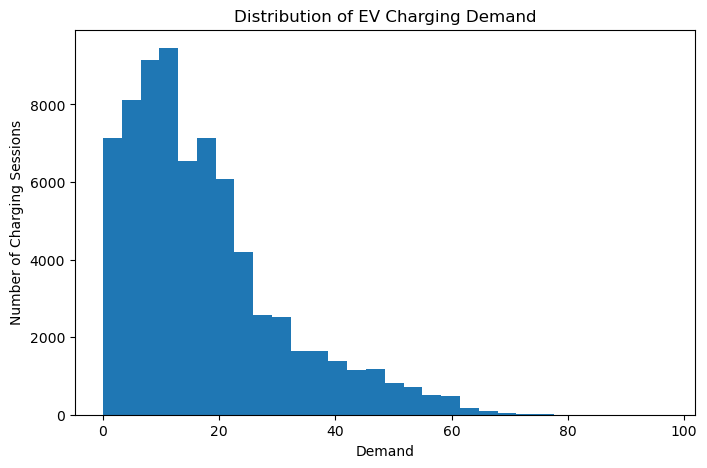

In [23]:
plt.figure(figsize=(8, 5))

plt.hist(df["Demand"], bins=30)

plt.xlabel("Demand")
plt.ylabel("Number of Charging Sessions")
plt.title("Distribution of EV Charging Demand")

plt.show()

In [24]:
charger_type_demand = (
    df.groupby("ChargerType")["Demand"]
      .mean()
      .sort_values(ascending=False)
)

charger_type_demand

ChargerType
1    18.946402
0    17.051995
Name: Demand, dtype: float64

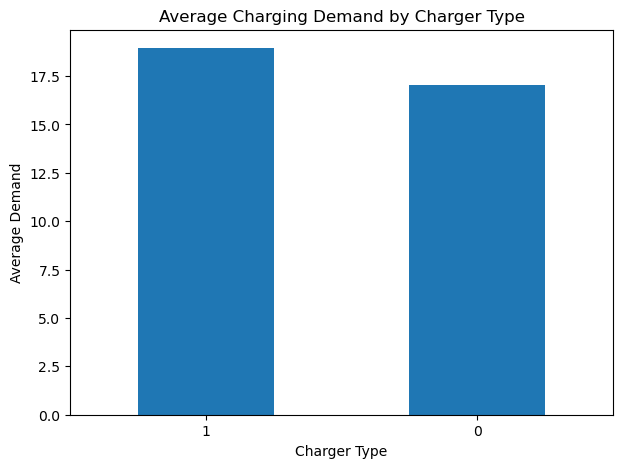

In [25]:
charger_type_demand.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.xlabel("Charger Type")
plt.ylabel("Average Demand")
plt.title("Average Charging Demand by Charger Type")

plt.xticks(rotation=0)
plt.show()

In [26]:
location_demand = (
    df.groupby("Location")["Demand"]
      .mean()
      .sort_values(ascending=False)
)

location_demand

Location
accommodation         29.055829
bus garage            28.587586
camping               25.525288
apartment             18.744879
public area           17.899891
restaurant            17.813123
public institution    17.399318
resort                17.280838
public parking lot    17.187510
golf                  16.718299
market                16.506272
company               16.248039
sightseeing           15.245129
hotel                 14.702966
Name: Demand, dtype: float64

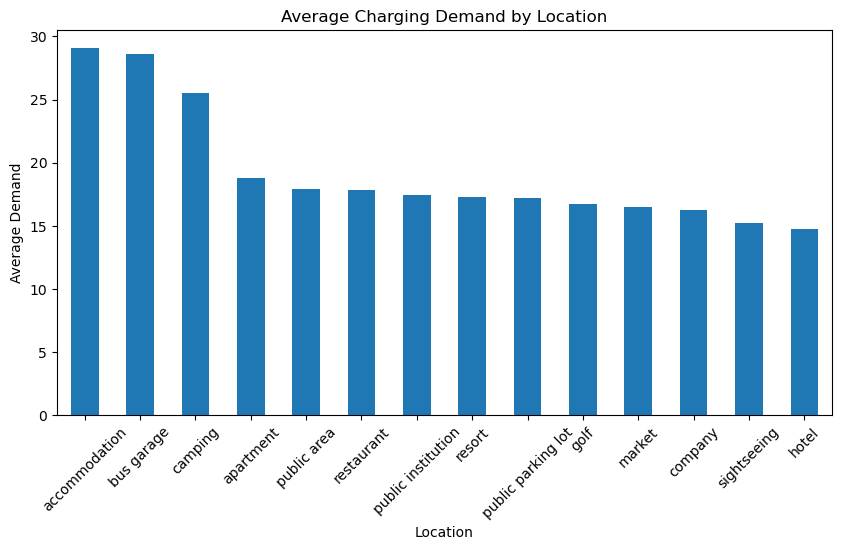

In [27]:
location_demand.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.xlabel("Location")
plt.ylabel("Average Demand")
plt.title("Average Charging Demand by Location")

plt.xticks(rotation=45)
plt.show()

In [28]:
df["StartDatetime"] = pd.to_datetime(df["StartDatetime"])

In [29]:
df["Hour"] = df["StartDatetime"].dt.hour

In [30]:
hourly_demand = (
    df.groupby("Hour")["Demand"]
      .mean()
)

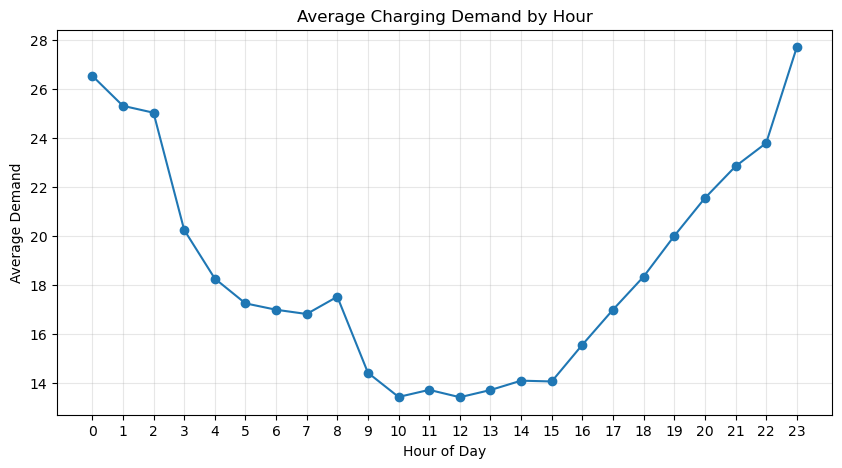

In [31]:
plt.figure(figsize=(10, 5))

plt.plot(hourly_demand.index, hourly_demand.values, marker="o")

plt.xlabel("Hour of Day")
plt.ylabel("Average Demand")
plt.title("Average Charging Demand by Hour")

plt.xticks(range(24))
plt.grid(True, alpha=0.3)

plt.show()

In [32]:
daily_demand = (
    df.set_index("StartDatetime")
      .resample("D")["Demand"]
      .mean()
)

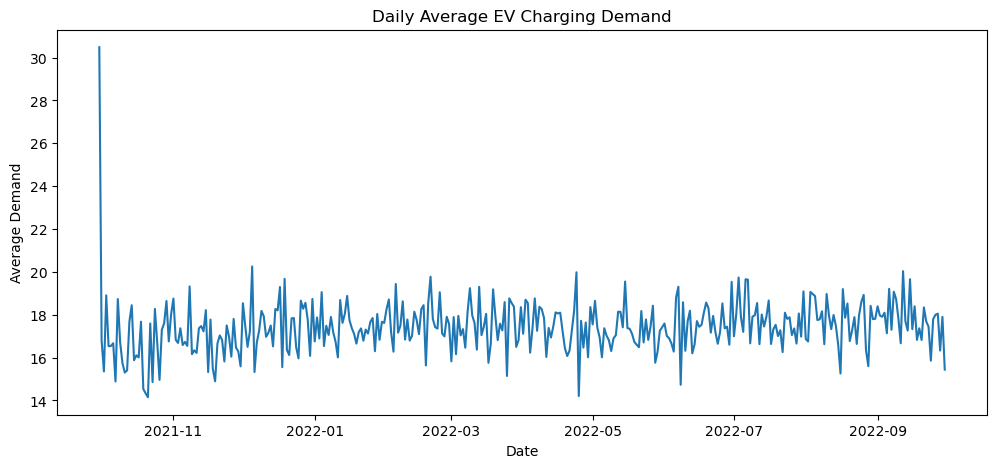

In [33]:
plt.figure(figsize=(12, 5))

plt.plot(daily_demand)

plt.xlabel("Date")
plt.ylabel("Average Demand")
plt.title("Daily Average EV Charging Demand")

plt.show()

### Feature Engineering

In [34]:
df["StartDatetime"] = pd.to_datetime(df["StartDatetime"])

In [35]:
df["EndDatetime"] = pd.to_datetime(df["EndDatetime"])

In [36]:
df["DayOfWeek"] = df["StartDatetime"].dt.dayofweek

In [37]:
df["Month"] = df["StartDatetime"].dt.month

In [38]:
df["IsWeekend"] = (df["DayOfWeek"] >= 5).astype(int)

In [39]:
def get_time_of_day(hour):
    if 5 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 17:
        return "Afternoon"
    elif 17 <= hour < 21:
        return "Evening"
    else:
        return "Night"

df["TimeOfDay"] = df["Hour"].apply(get_time_of_day)

In [40]:
demand_median = df["Demand"].median()

demand_median

14.1

In [41]:
df["Demand_Category"] = np.where(
    df["Demand"] >= demand_median,
    "High Demand",
    "Normal Demand"
)

In [42]:
df["Demand_Category"].value_counts()

Demand_Category
High Demand      36439
Normal Demand    36387
Name: count, dtype: int64

In [43]:
df["Demand_Category"].value_counts(normalize=True) * 100

Demand_Category
High Demand      50.035702
Normal Demand    49.964298
Name: proportion, dtype: float64

In [44]:
df[
    [
        "StartDatetime",
        "Demand",
        "Hour",
        "DayOfWeek",
        "Month",
        "IsWeekend",
        "TimeOfDay",
        "Demand_Category"
    ]
].head(10)

,StartDatetime,Demand,Hour,DayOfWeek,Month,IsWeekend,TimeOfDay,Demand_Category
0,2022-09-15 20:54:00,20.36,20,3,9,0,Evening,High Demand
1,2022-09-14 20:01:00,10.19,20,2,9,0,Evening,Normal Demand
2,2022-09-14 18:54:00,6.78,18,2,9,0,Evening,Normal Demand
3,2022-09-29 18:32:00,37.65,18,3,9,0,Evening,High Demand
4,2022-09-25 19:30:00,33.81,19,6,9,1,Evening,High Demand
5,2022-09-24 14:51:00,8.17,14,5,9,1,Afternoon,Normal Demand
6,2022-08-11 18:28:00,6.38,18,3,8,0,Evening,Normal Demand
7,2022-08-10 19:37:00,55.17,19,2,8,0,Evening,High Demand
8,2022-08-09 19:43:00,6.68,19,1,8,0,Evening,Normal Demand
9,2022-08-07 19:51:00,12.57,19,6,8,1,Evening,Normal Demand


### Regression

In [45]:
features = [
    "ChargerCompany",
    "Location",
    "ChargerType",
    "Duration",
    "Hour",
    "DayOfWeek",
    "Month",
    "IsWeekend",
    "TimeOfDay"
]

X = df[features]
y = df["Demand"]

In [46]:
X.head()

,ChargerCompany,Location,ChargerType,Duration,Hour,DayOfWeek,Month,IsWeekend,TimeOfDay
0,1,hotel,0,185,20,3,9,0,Evening
1,1,hotel,0,90,20,2,9,0,Evening
2,1,hotel,0,60,18,2,9,0,Evening
3,1,hotel,0,344,18,3,9,0,Evening
4,1,hotel,0,300,19,6,9,1,Evening


In [47]:
y.head()

0    20.36
1    10.19
2     6.78
3    37.65
4    33.81
Name: Demand, dtype: float64

In [48]:
X.shape

(72826, 9)

In [49]:
y.shape

(72826,)

In [50]:
categorical_features = [
    "ChargerCompany",
    "Location",
    "ChargerType",
    "TimeOfDay"
]

In [51]:
numerical_features = [
    "Duration",
    "Hour",
    "DayOfWeek",
    "Month",
    "IsWeekend"
]

In [52]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [53]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (58260, 9)
Testing data: (14566, 9)


In [54]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_features = [
    "ChargerCompany",
    "Location",
    "ChargerType",
    "TimeOfDay"
]

numerical_features = [
    "Duration",
    "Hour",
    "DayOfWeek",
    "Month",
    "IsWeekend"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [55]:
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

In [56]:
models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    ),

    "XGBoost": XGBRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1,
        objective="reg:squarederror"
    ),

    "LightGBM": LGBMRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )
}

In [57]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

results = []
trained_models = {}

In [58]:
for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })

    trained_models[name] = pipeline

In [59]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

results_df

,Model,MAE,MSE,RMSE,R2
0,XGBoost,3.321935,35.079183,5.922768,0.805330
1,LightGBM,3.386587,35.783428,5.981925,0.801422
2,Random Forest,3.411977,38.076394,6.170607,0.788697
3,Gradient Boosting,3.686926,41.041375,6.406354,0.772243
4,Decision Tree,4.259924,68.387912,8.269698,0.620485
5,Linear Regression,5.608011,77.258179,8.789663,0.571260


In [60]:
results_df.round(4)

,Model,MAE,MSE,RMSE,R2
0,XGBoost,3.3219,35.0792,5.9228,0.8053
1,LightGBM,3.3866,35.7834,5.9819,0.8014
2,Random Forest,3.4120,38.0764,6.1706,0.7887
3,Gradient Boosting,3.6869,41.0414,6.4064,0.7722
4,Decision Tree,4.2599,68.3879,8.2697,0.6205
5,Linear Regression,5.6080,77.2582,8.7897,0.5713


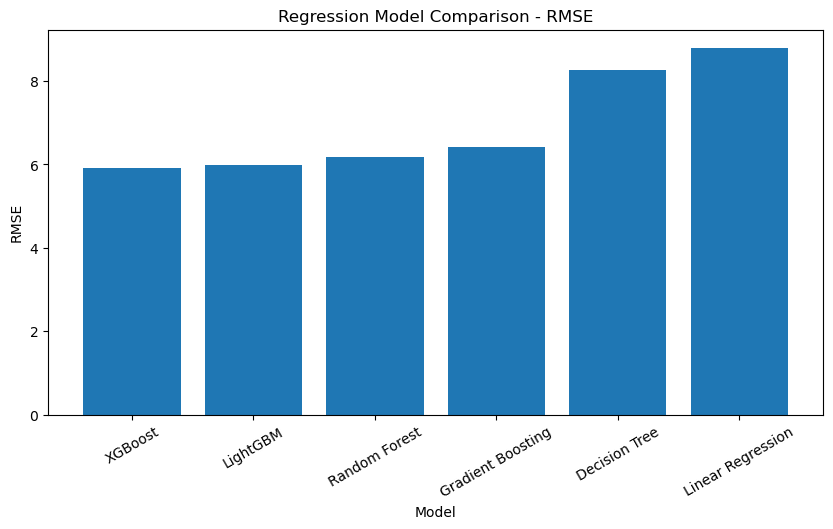

In [61]:
plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Model"],
    results_df["RMSE"]
)

plt.xlabel("Model")
plt.ylabel("RMSE")
plt.title("Regression Model Comparison - RMSE")

plt.xticks(rotation=30)
plt.show()

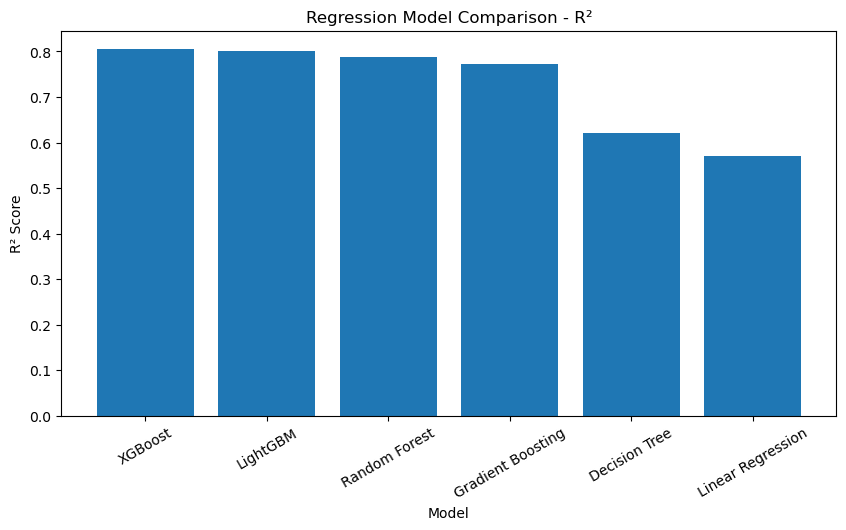

In [62]:
plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Model"],
    results_df["R2"]
)

plt.xlabel("Model")
plt.ylabel("R² Score")
plt.title("Regression Model Comparison - R²")

plt.xticks(rotation=30)
plt.show()

In [63]:
best_model_name = results_df.loc[
    results_df["RMSE"].idxmin(),
    "Model"
]

best_model_name

'XGBoost'

In [64]:
best_model = trained_models[best_model_name]

### hyperparameter tuning


In [65]:
from sklearn.model_selection import RandomizedSearchCV

In [66]:
xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        objective="reg:squarederror",
        random_state=42,
        n_jobs=1
    ))
])

In [67]:
param_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [3, 5, 7],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__subsample": [0.8, 1.0],
    "model__colsample_bytree": [0.8, 1.0],
    "model__min_child_weight": [1, 3, 5]
}

In [68]:
xgb_random_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_grid,
    n_iter=10,
    scoring="neg_root_mean_squared_error",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

In [69]:
xgb_random_search.fit(X_train, y_train)

Fitting 3 folds for each of 10 candidates, totalling 30 fits


,estimator,"Pipeline(step...=None, ...))])"
,param_distributions,"{'model__colsample_bytree': [0.8, 1.0], 'model__learning_rate': [0.03, 0.05, ...], 'model__max_depth': [3, 5, ...], 'model__min_child_weight': [1, 3, ...], ...}"
,n_iter,10
,scoring,'neg_root_mean_squared_error'
,n_jobs,-1
,refit,True
,cv,3
,verbose,1
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [70]:
xgb_random_search.best_params_

{'model__subsample': 0.8,
 'model__n_estimators': 200,
 'model__min_child_weight': 5,
 'model__max_depth': 7,
 'model__learning_rate': 0.05,
 'model__colsample_bytree': 1.0}

In [71]:
xgb_random_search.best_score_

np.float64(-6.016228925007344)

In [72]:
-xgb_random_search.best_score_

np.float64(6.016228925007344)

In [73]:
tuned_xgb = xgb_random_search.best_estimator_

y_pred_tuned = tuned_xgb.predict(X_test)

In [74]:
tuned_mae = mean_absolute_error(y_test, y_pred_tuned)

tuned_mse = mean_squared_error(y_test, y_pred_tuned)

tuned_rmse = np.sqrt(tuned_mse)

tuned_r2 = r2_score(y_test, y_pred_tuned)

print("Tuned XGBoost")
print("MAE :", tuned_mae)
print("MSE :", tuned_mse)
print("RMSE:", tuned_rmse)
print("R2  :", tuned_r2)

Tuned XGBoost
MAE : 3.3001414093595383
MSE : 34.61007806863878
RMSE: 5.883033067103973
R2  : 0.8079331515330376


### Feature Importance

In [75]:
xgb_model = tuned_xgb.named_steps["model"]

In [76]:
feature_names = tuned_xgb.named_steps["preprocessor"].get_feature_names_out()

In [77]:
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

importance_df.head(15)

,Feature,Importance
0,cat__ChargerType_0,0.398896
1,num__Duration,0.269802
2,cat__ChargerCompany_0,0.030437
3,cat__Location_camping,0.026937
4,cat__Location_hotel,0.025435
5,cat__TimeOfDay_Morning,0.024338
6,cat__Location_apartment,0.022622
7,cat__Location_public institution,0.017842
8,cat__Location_resort,0.017094
9,cat__Location_restaurant,0.016342


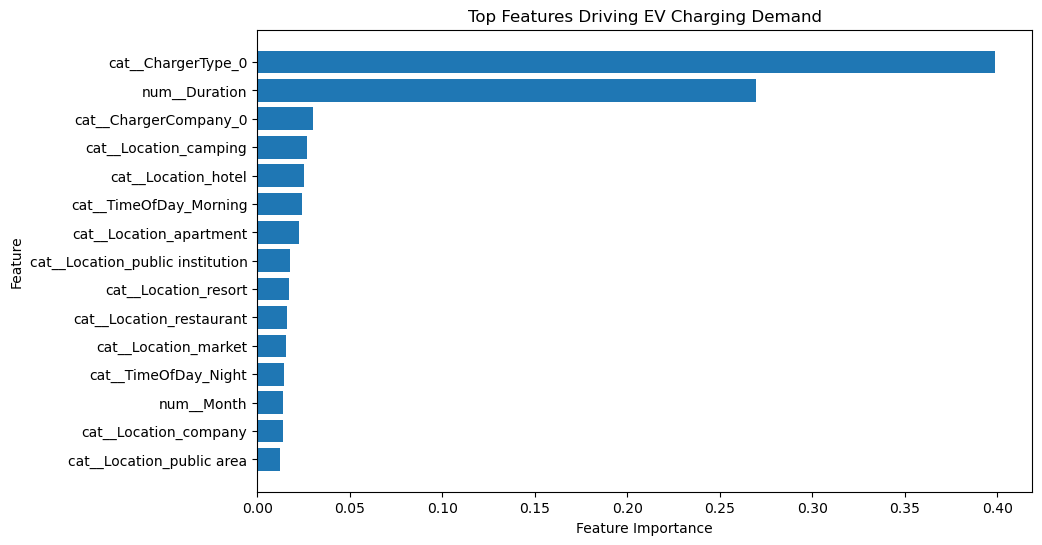

In [78]:
top_features = importance_df.head(15)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top Features Driving EV Charging Demand")

plt.show()

The XGBoost model identifies `charger type` and `charging duration` as the most influential predictors of EV charging demand.

In [79]:
import joblib

joblib.dump(tuned_xgb, "final_xgboost_demand_model.pkl")

['final_xgboost_demand_model.pkl']

In [80]:
loaded_model = joblib.load("final_xgboost_demand_model.pkl")

In [81]:
test_predictions = loaded_model.predict(X_test)

test_predictions[:5]

array([13.054047, 24.911634, 13.362976, 11.095072, 40.199993],
      dtype=float32)

In [142]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

test_predictions = loaded_model.predict(X_test)

mae = mean_absolute_error(y_test, test_predictions)
mse = mean_squared_error(y_test, test_predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, test_predictions)

print("Regression Model Verification")
print(f"MAE  : {mae:.6f}")
print(f"MSE  : {mse:.6f}")
print(f"RMSE : {rmse:.6f}")
print(f"R2   : {r2:.6f}")


Regression Model Verification
MAE  : 3.300141
MSE  : 34.610078
RMSE : 5.883033
R2   : 0.807933


# Classification

In [82]:
classification_features = [
    "ChargerCompany",
    "Location",
    "ChargerType",
    "Duration",
    "Hour",
    "DayOfWeek",
    "Month",
    "IsWeekend",
    "TimeOfDay"
]

In [83]:
X_cls = df[classification_features]
y_cls = df["Demand_Category"]

In [84]:
print("Features:", X_cls.shape)
print("Target:", y_cls.shape)

Features: (72826, 9)
Target: (72826,)


In [85]:
from sklearn.model_selection import train_test_split

X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls,
    y_cls,
    test_size=0.20,
    random_state=42,
    stratify=y_cls
)

In [86]:
print("Training:", X_train_cls.shape)
print("Testing :", X_test_cls.shape)

print("\nTraining distribution:")
print(y_train_cls.value_counts(normalize=True) * 100)

print("\nTesting distribution:")
print(y_test_cls.value_counts(normalize=True) * 100)

Training: (58260, 9)
Testing : (14566, 9)

Training distribution:
Demand_Category
High Demand      50.036045
Normal Demand    49.963955
Name: proportion, dtype: float64

Testing distribution:
Demand_Category
High Demand      50.034327
Normal Demand    49.965673
Name: proportion, dtype: float64


In [87]:
categorical_features_cls = [
    "ChargerCompany",
    "Location",
    "ChargerType",
    "TimeOfDay"
]

numerical_features_cls = [
    "Duration",
    "Hour",
    "DayOfWeek",
    "Month",
    "IsWeekend"
]

In [88]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor_cls = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features_cls
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features_cls
        )
    ]
)

In [89]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

In [90]:
classification_models = {

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        n_jobs=-1
    ),

    "SVM": SVC(
        probability=True,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1,
        eval_metric="logloss"
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )
}

In [91]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_cls_encoded = label_encoder.fit_transform(y_train_cls)
y_test_cls_encoded = label_encoder.transform(y_test_cls)

In [92]:
label_encoder.classes_

array(['High Demand', 'Normal Demand'], dtype=object)

In [93]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

In [94]:
from sklearn.pipeline import Pipeline

classification_results = []
trained_classifiers = {}

for name, model in classification_models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor_cls),
        ("model", model)
    ])

    pipeline.fit(
        X_train_cls,
        y_train_cls_encoded
    )

    y_pred = pipeline.predict(X_test_cls)
    y_prob = pipeline.predict_proba(X_test_cls)[:, 1]

    accuracy = accuracy_score(
        y_test_cls_encoded,
        y_pred
    )

    precision = precision_score(
        y_test_cls_encoded,
        y_pred
    )

    recall = recall_score(
        y_test_cls_encoded,
        y_pred
    )

    f1 = f1_score(
        y_test_cls_encoded,
        y_pred
    )

    roc_auc = roc_auc_score(
        y_test_cls_encoded,
        y_prob
    )

    classification_results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC-AUC": roc_auc
    })

    trained_classifiers[name] = pipeline

In [95]:
classification_results_df = pd.DataFrame(
    classification_results
)

classification_results_df = (
    classification_results_df
    .sort_values(
        by="F1",
        ascending=False
    )
    .reset_index(drop=True)
)

classification_results_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,XGBoost,0.898462,0.927466,0.864386,0.894815,0.960133
1,LightGBM,0.896059,0.927470,0.859165,0.892011,0.958970
2,Random Forest,0.891528,0.912420,0.866035,0.888623,0.952993
3,SVM,0.888370,0.919911,0.850646,0.883923,0.944475
4,Decision Tree,0.853288,0.851497,0.855592,0.853540,0.854257
5,Logistic Regression,0.841343,0.862820,0.811487,0.836366,0.909652
6,KNN,0.834272,0.847727,0.814647,0.830858,0.908982


## Tune Classification XGBoost

In [96]:
xgb_cls_pipeline = Pipeline([
    ("preprocessor", preprocessor_cls),
    ("model", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    ))
])

In [97]:
xgb_cls_params = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [3, 5, 7],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__subsample": [0.8, 1.0],
    "model__colsample_bytree": [0.8, 1.0],
    "model__min_child_weight": [1, 3, 5]
}

In [98]:
from sklearn.model_selection import RandomizedSearchCV

xgb_cls_random_search = RandomizedSearchCV(
    estimator=xgb_cls_pipeline,
    param_distributions=xgb_cls_params,
    n_iter=10,
    scoring="f1",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

In [99]:
xgb_cls_random_search.fit(
    X_train_cls,
    y_train_cls_encoded
)

Fitting 3 folds for each of 10 candidates, totalling 30 fits


,estimator,"Pipeline(step...=None, ...))])"
,param_distributions,"{'model__colsample_bytree': [0.8, 1.0], 'model__learning_rate': [0.03, 0.05, ...], 'model__max_depth': [3, 5, ...], 'model__min_child_weight': [1, 3, ...], ...}"
,n_iter,10
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,3
,verbose,1
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [100]:
xgb_cls_random_search.best_params_

{'model__subsample': 0.8,
 'model__n_estimators': 100,
 'model__min_child_weight': 1,
 'model__max_depth': 7,
 'model__learning_rate': 0.1,
 'model__colsample_bytree': 0.8}

In [101]:
xgb_cls_random_search.best_score_

np.float64(0.8953367149421432)

In [102]:
tuned_xgb_cls = xgb_cls_random_search.best_estimator_

y_pred_cls = tuned_xgb_cls.predict(X_test_cls)
y_prob_cls = tuned_xgb_cls.predict_proba(X_test_cls)[:, 1]

In [103]:
tuned_accuracy = accuracy_score(
    y_test_cls_encoded,
    y_pred_cls
)

tuned_precision = precision_score(
    y_test_cls_encoded,
    y_pred_cls
)

tuned_recall = recall_score(
    y_test_cls_encoded,
    y_pred_cls
)

tuned_f1 = f1_score(
    y_test_cls_encoded,
    y_pred_cls
)

tuned_roc_auc = roc_auc_score(
    y_test_cls_encoded,
    y_prob_cls
)

print("Tuned XGBoost Classification")
print("Accuracy :", tuned_accuracy)
print("Precision:", tuned_precision)
print("Recall   :", tuned_recall)
print("F1       :", tuned_f1)
print("ROC-AUC  :", tuned_roc_auc)

Tuned XGBoost Classification
Accuracy : 0.899354661540574
Precision: 0.9326980345443716
Recall   : 0.8606760098928277
F1       : 0.8952408174932114
ROC-AUC  : 0.95996320957646


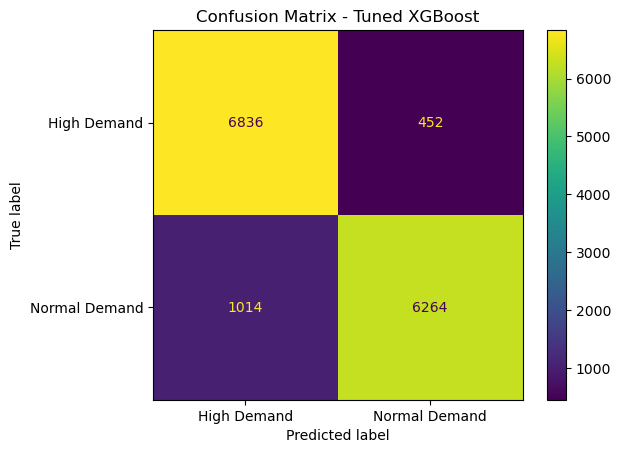

In [104]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test_cls_encoded,
    y_pred_cls
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

disp.plot()

plt.title("Confusion Matrix - Tuned XGBoost")
plt.show()

In [105]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test_cls_encoded,
        y_pred_cls,
        target_names=label_encoder.classes_
    )
)

               precision    recall  f1-score   support

  High Demand       0.87      0.94      0.90      7288
Normal Demand       0.93      0.86      0.90      7278

     accuracy                           0.90     14566
    macro avg       0.90      0.90      0.90     14566
 weighted avg       0.90      0.90      0.90     14566



In [106]:
joblib.dump(
    tuned_xgb_cls,
    "final_xgboost_demand_classifier.pkl"
)

['final_xgboost_demand_classifier.pkl']

In [107]:
joblib.dump(
    label_encoder,
    "demand_label_encoder.pkl"
)

['demand_label_encoder.pkl']

In [150]:

import joblib
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Load the saved classification model
loaded_classifier = joblib.load(
    "final_xgboost_demand_classifier.pkl"
)

# Predict on the original test dataset
test_predictions = loaded_classifier.predict(X_test_cls)
test_probabilities = loaded_classifier.predict_proba(X_test_cls)[:, 1]

# Evaluate against the encoded test labels
print("Saved XGBoost Classification Model Verification")
print("-" * 50)

print(f"Accuracy  : {accuracy_score(y_test_cls_encoded, test_predictions):.6f}")
print(f"Precision : {precision_score(y_test_cls_encoded, test_predictions):.6f}")
print(f"Recall    : {recall_score(y_test_cls_encoded, test_predictions):.6f}")
print(f"F1 Score  : {f1_score(y_test_cls_encoded, test_predictions):.6f}")
print(f"ROC-AUC   : {roc_auc_score(y_test_cls_encoded, test_probabilities):.6f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test_cls_encoded,
        test_predictions,
        target_names=label_encoder.classes_
    )
)


Saved XGBoost Classification Model Verification
--------------------------------------------------
Accuracy  : 0.899355
Precision : 0.932698
Recall    : 0.860676
F1 Score  : 0.895241
ROC-AUC   : 0.959963

Classification Report:
               precision    recall  f1-score   support

  High Demand       0.87      0.94      0.90      7288
Normal Demand       0.93      0.86      0.90      7278

     accuracy                           0.90     14566
    macro avg       0.90      0.90      0.90     14566
 weighted avg       0.90      0.90      0.90     14566



## SHAP + LIME explainability

In [108]:
import shap

In [109]:
xgb_model = tuned_xgb.named_steps["model"]

In [110]:
preprocessor = tuned_xgb.named_steps["preprocessor"]

In [111]:
X_test_transformed = preprocessor.transform(X_test)

In [112]:
feature_names = preprocessor.get_feature_names_out()

In [113]:
X_test_transformed_df = pd.DataFrame(
    X_test_transformed,
    columns=feature_names,
    index=X_test.index
)

In [114]:
explainer = shap.TreeExplainer(xgb_model)

In [115]:
X_shap = X_test_transformed_df.sample(
    n=min(1000, len(X_test_transformed_df)),
    random_state=42
)

In [116]:
shap_values = explainer.shap_values(X_shap)

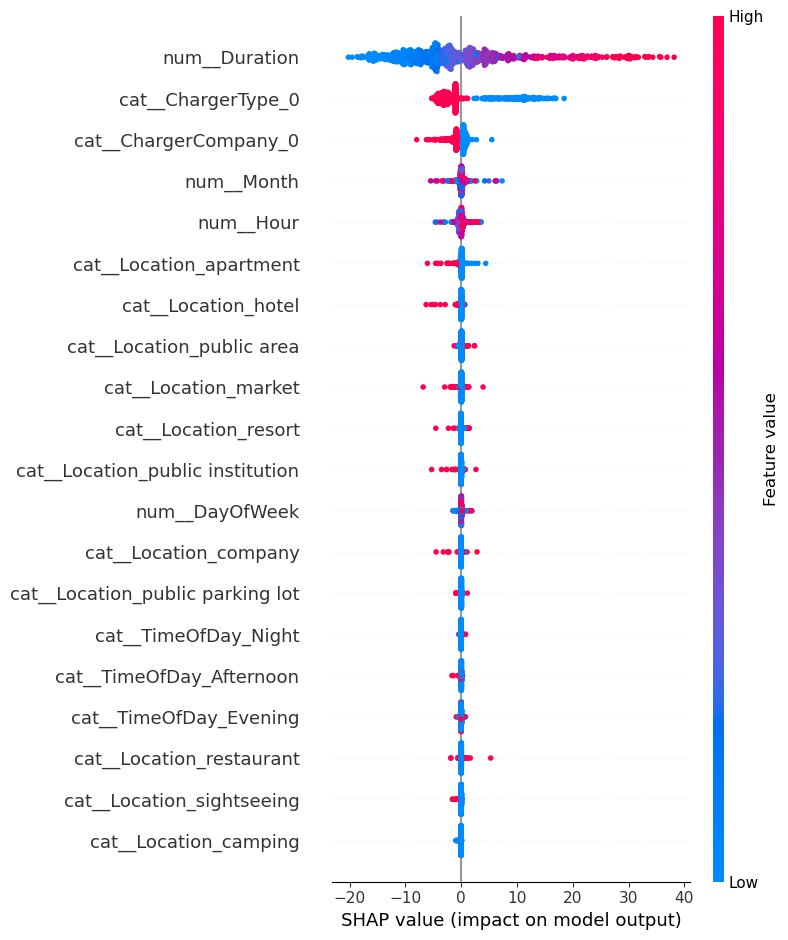

In [117]:
shap.summary_plot(
    shap_values,
    X_shap,
    show=True
)

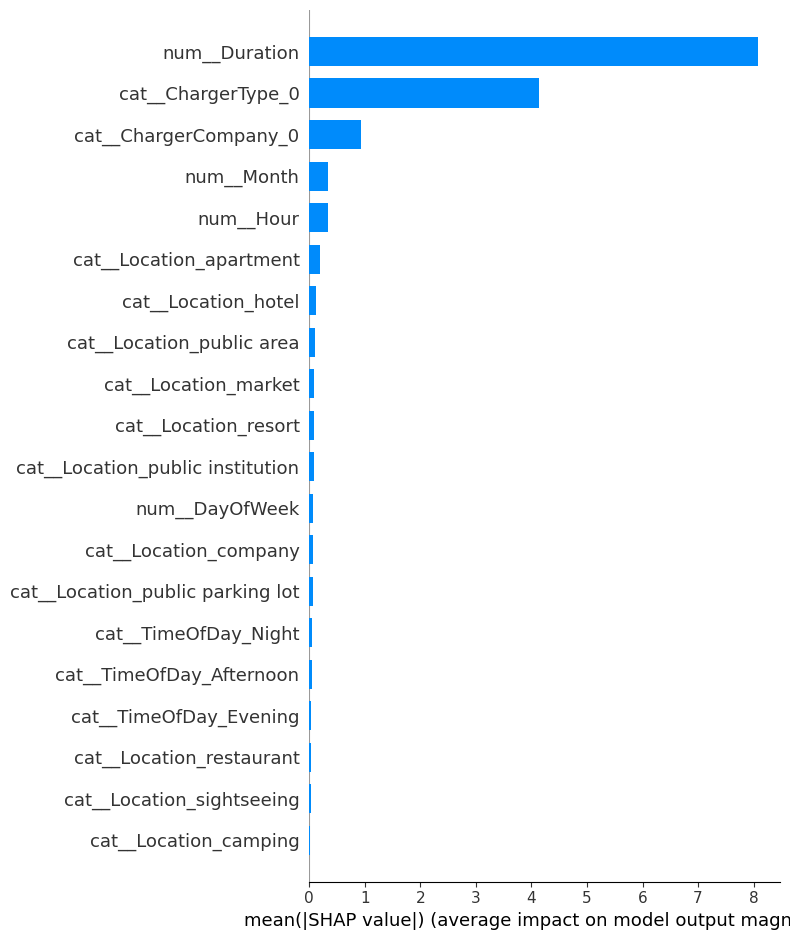

In [118]:
shap.summary_plot(
    shap_values,
    X_shap,
    plot_type="bar",
    show=True
)

### SHAP for Classification

In [119]:
xgb_cls_model = tuned_xgb_cls.named_steps["model"]

preprocessor_cls_final = tuned_xgb_cls.named_steps["preprocessor"]

In [120]:
X_test_cls_transformed = preprocessor_cls_final.transform(
    X_test_cls
)

In [121]:
feature_names_cls = (
    preprocessor_cls_final
    .get_feature_names_out()
)

In [122]:
X_test_cls_transformed_df = pd.DataFrame(
    X_test_cls_transformed,
    columns=feature_names_cls,
    index=X_test_cls.index
)

In [123]:
X_shap_cls = X_test_cls_transformed_df.sample(
    n=min(1000, len(X_test_cls_transformed_df)),
    random_state=42
)

In [124]:
explainer_cls = shap.TreeExplainer(
    xgb_cls_model
)

In [125]:
shap_values_cls = explainer_cls.shap_values(
    X_shap_cls
)

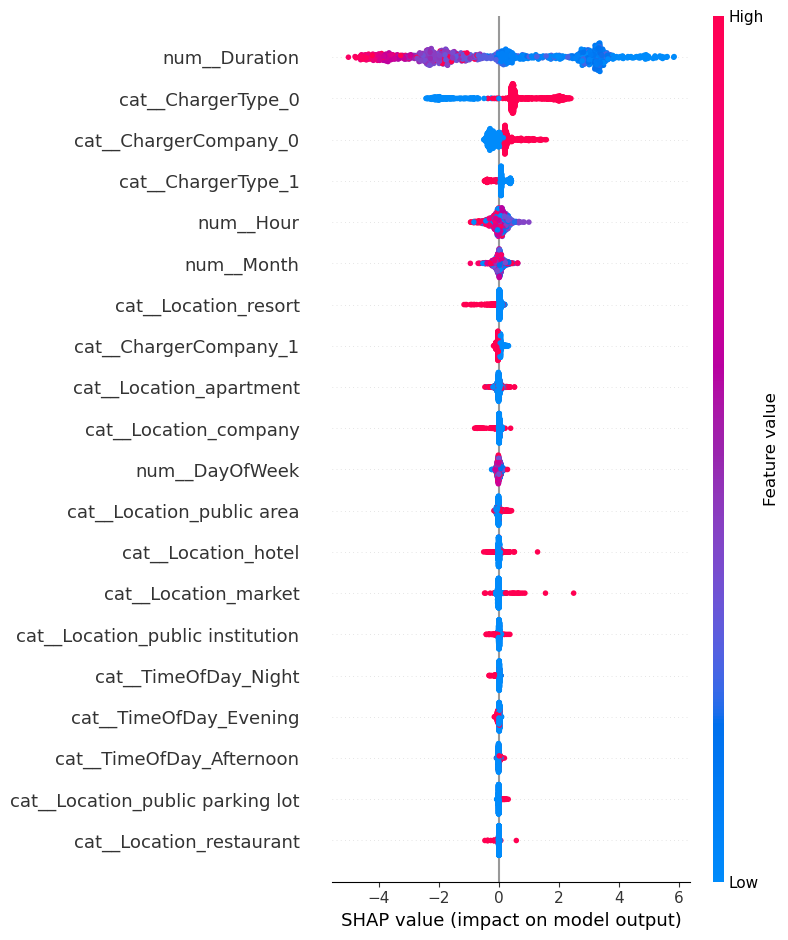

In [126]:
shap.summary_plot(
    shap_values_cls,
    X_shap_cls,
    show=True
)

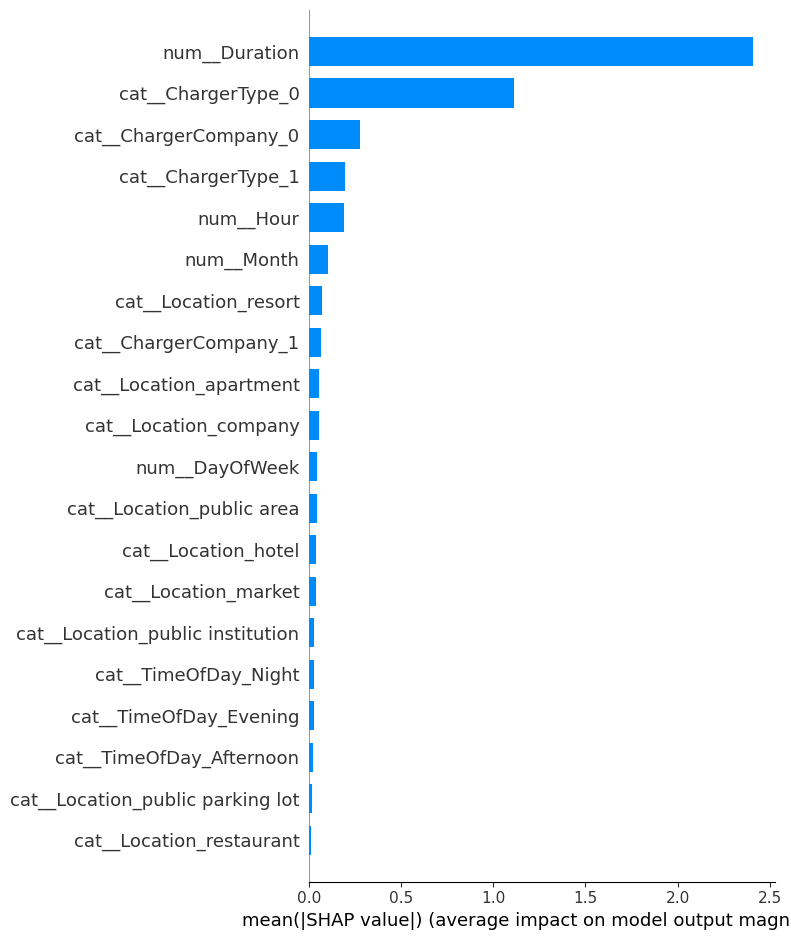

In [127]:
shap.summary_plot(
    shap_values_cls,
    X_shap_cls,
    plot_type="bar",
    show=True
)

### LIME

In [128]:
import lime

In [129]:
from lime.lime_tabular import LimeTabularExplainer

### LIME Regression

In [130]:
X_train_transformed = preprocessor.transform(X_train)

In [131]:
lime_explainer = LimeTabularExplainer(
    training_data=np.asarray(X_train_transformed),
    feature_names=feature_names.tolist(),
    mode="regression",
    random_state=42
)

In [132]:
sample_index = 0

sample = X_test_transformed_df.iloc[
    sample_index
].values

In [133]:
lime_explanation = lime_explainer.explain_instance(
    sample,
    xgb_model.predict,
    num_features=10
)

In [134]:
lime_explanation.as_list()

[('num__Duration <= -0.76', -22.099531012484988),
 ('cat__Location_hotel <= 0.00', 6.359609797984715),
 ('cat__Location_golf <= 0.00', 4.409982621388154),
 ('cat__Location_sightseeing <= 0.00', 3.429115367402341),
 ('cat__Location_bus garage <= 0.00', -3.1543606330503655),
 ('cat__Location_apartment <= 0.00', 2.9521603581637716),
 ('cat__Location_market <= 0.00', -2.8568735655229607),
 ('cat__Location_public institution <= 0.00', -2.4090292514654665),
 ('cat__Location_restaurant <= 0.00', 1.6452076809225762),
 ('cat__Location_accommodation <= 0.00', -1.3623466933525383)]

In [135]:
for feature, contribution in lime_explanation.as_list():
    print(f"{feature}: {contribution:.4f}")

num__Duration <= -0.76: -22.0995
cat__Location_hotel <= 0.00: 6.3596
cat__Location_golf <= 0.00: 4.4100
cat__Location_sightseeing <= 0.00: 3.4291
cat__Location_bus garage <= 0.00: -3.1544
cat__Location_apartment <= 0.00: 2.9522
cat__Location_market <= 0.00: -2.8569
cat__Location_public institution <= 0.00: -2.4090
cat__Location_restaurant <= 0.00: 1.6452
cat__Location_accommodation <= 0.00: -1.3623


In [136]:
sample_prediction = xgb_model.predict(
    sample.reshape(1, -1)
)[0]

print("Predicted Demand:", sample_prediction)

Predicted Demand: 13.054047


### LIME for classification

In [137]:
X_train_cls_transformed = (
    preprocessor_cls_final.transform(X_train_cls)
)

In [138]:
lime_cls_explainer = LimeTabularExplainer(
    training_data=np.asarray(
        X_train_cls_transformed
    ),
    feature_names=feature_names_cls.tolist(),
    class_names=label_encoder.classes_.tolist(),
    mode="classification",
    random_state=42
)

In [139]:
sample_index_cls = 0

sample_cls = X_test_cls_transformed_df.iloc[
    sample_index_cls
].values

In [140]:
lime_cls_explanation = lime_cls_explainer.explain_instance(
    sample_cls,
    xgb_cls_model.predict_proba,
    labels=(0, 1),
    num_features=10
)

In [141]:
for class_id in lime_cls_explanation.available_labels():
    class_name = label_encoder.classes_[class_id]

    print(f"\nExplanation for: {class_name}")

    for feature, weight in lime_cls_explanation.as_list(label=class_id):
        print(f"{feature}: {weight:.4f}")


Explanation for: High Demand
-0.27 < num__Duration <= 0.35: 0.1694
cat__Location_golf <= 0.00: 0.1361
cat__Location_hotel <= 0.00: 0.1013
cat__ChargerType_1 <= 0.00: -0.0826
cat__Location_accommodation <= 0.00: -0.0530
cat__Location_restaurant <= 0.00: 0.0435
cat__ChargerCompany_0 <= 0.00: 0.0347
cat__Location_apartment > 0.00: -0.0312
cat__Location_public area <= 0.00: 0.0250
cat__Location_bus garage <= 0.00: -0.0108

Explanation for: Normal Demand
-0.27 < num__Duration <= 0.35: -0.1694
cat__Location_golf <= 0.00: -0.1361
cat__Location_hotel <= 0.00: -0.1013
cat__ChargerType_1 <= 0.00: 0.0826
cat__Location_accommodation <= 0.00: 0.0530
cat__Location_restaurant <= 0.00: -0.0435
cat__ChargerCompany_0 <= 0.00: -0.0347
cat__Location_apartment > 0.00: 0.0312
cat__Location_public area <= 0.00: -0.0250
cat__Location_bus garage <= 0.00: 0.0108
